# <center>Introduction to classification algorithms (using the whole data)</center>

### Classifiers:
- #### Decision Tree (DT)
- #### Logistic Regression (LR)
- #### k-Nearest Neighbors (k-NN)
- #### Support Vector Machine (SVM)
- #### Time series k-NN
- #### Neural Network (NN)

___
# Modules

To enable autoreloading of all modules, it is necessary to install IPython by executing the following command: **pip install ipython**

Example of module importation:
```python
from Modules import data_manipulation_module as dmm
```

| Modul names                   | Description                                             |
|-------------------------------|---------------------------------------------------------|
| data_manipulation_module      | Functions for data manipulation                         |
| nts_classification_module     | Functions for non-time series classification algorithms |
| ts_classification_module      | Functions for time series classification algorithms     |
| validation_and_results_module | Functions for validation and results                    |
| param_tuning_module           | Functions for parameter tuning                          |
| dim_reduction_module          | Functions for dimensionality reduction                  |
| plots_module                  | Functions for plotting                                  |

In [4]:
#autoreload all the modules
#If an error occurs after importing a module, re-executing these statements should resolve the issue.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## 1. Data loading

In [2]:
import glob
import pandas as pd

#beacuse of k-nn
from warnings import simplefilter
simplefilter(action='ignore', category = FutureWarning)

#Numpy version check
import numpy as np
np.__version__
#delete the comment before pip if the version is not 1.21.4
#pip install --upgrade numpy==1.21.4 --user

'1.21.4'

In [5]:
from Modules import data_manipulation_module as dmm

In [6]:
#Saving the files names
NP_csv_files = glob.glob('/tf/notebooks/DatasCSV/NP/*.csv')
KT_csv_files = glob.glob('/tf/notebooks/DatasCSV/KT/*.csv')
SU_csv_files = glob.glob('/tf/notebooks/DatasCSV/SU/*.csv')

NP_csv_files = sorted(NP_csv_files)
KT_csv_files = sorted(KT_csv_files)
SU_csv_files = sorted(SU_csv_files)

In [7]:
#Loading_data(files, separator, col_names)
  # col_names: list of the column names or None if the data already contains the names for the columns
NP_df_list = dmm.Loading_data(NP_csv_files, ";", None)
KT_df_list = dmm.Loading_data(KT_csv_files, ";", None)
SU_df_list = dmm.Loading_data(SU_csv_files, ";", None)

In [8]:
NP_df_list[0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.118529,-0.015860,0.367277,0.482652,-0.326916,-0.812538,0.642312,0.762788,0.074571,0.594823,...,-0.583559,0.578939,0.569462,-0.013975,-0.002687,0.006508,-0.021289,-0.230186,0.452584,-1.198475
1,0.117837,-0.016283,0.367878,0.470070,-0.331100,-0.818200,0.649242,0.757665,0.066332,0.597381,...,-0.585849,0.583027,0.562902,-0.006929,-0.003082,0.006237,-0.019702,-0.142757,0.343896,-1.202884
2,0.117591,-0.016579,0.368282,0.464992,-0.333945,-0.819944,0.652489,0.755208,0.062384,0.597824,...,-0.586203,0.584588,0.560911,-0.007013,-0.007571,0.011385,-0.058685,-0.138019,0.321906,-1.201741
3,0.117164,-0.017204,0.369130,0.457999,-0.337982,-0.822223,0.657503,0.751245,0.057376,0.597736,...,-0.586036,0.587470,0.558068,-0.000156,-0.008891,0.010383,-0.064197,-0.068266,0.171226,-1.198312
4,0.116830,-0.017850,0.369779,0.457318,-0.342555,-0.820707,0.656666,0.752381,0.051810,0.599175,...,-0.587479,0.583116,0.561108,-0.000627,-0.011057,0.008655,-0.058588,0.077483,-0.011222,-1.195536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3433,0.142431,-0.019635,0.426738,0.857629,-0.247396,-0.450902,0.299046,0.953128,0.045724,0.417392,...,-0.417144,0.192595,0.888198,-0.000274,-0.002466,-0.001380,-2.250799,1.036829,4.962650,-0.540414
3434,0.142378,-0.019676,0.426621,0.861480,-0.264215,-0.433691,0.312973,0.948748,0.043565,0.398884,...,-0.397702,0.195262,0.896495,-0.000363,0.001951,-0.006721,0.063972,0.508576,-0.221638,-0.391330
3435,0.142191,-0.019512,0.425955,0.863868,-0.297715,-0.406378,0.342397,0.938687,0.040040,0.368470,...,-0.365923,0.194084,0.910181,-0.000650,-0.000191,-0.007957,0.166514,0.675894,-0.078584,-0.081241
3436,0.142137,-0.019330,0.425178,0.871721,-0.299333,-0.388004,0.338906,0.940116,0.036006,0.352910,...,-0.350691,0.183105,0.918415,-0.000539,0.005146,-0.012726,0.200262,0.397835,-0.071289,0.174962


In [9]:
#Target vairable files loading
NP_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Needle_Passing.txt', " ", None)
KT_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Knot_Tying.txt', " ", None)
SU_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Suturing.txt', " ", None)

In [10]:
NP_class

,file,Experience,GRS,OSATS_1,OSATS_2,OSATS_3,OSATS_4,OSATS_5,OSATS_6
0,Needle_Passing_B001,N,8,1,1,1,2,1,2
1,Needle_Passing_B002,N,8,1,1,1,2,1,2
2,Needle_Passing_B003,N,14,2,2,2,3,2,3
3,Needle_Passing_B004,N,19,3,3,3,4,3,3
4,Needle_Passing_C001,I,11,1,2,1,3,2,2
5,Needle_Passing_C002,I,9,1,1,1,3,1,2
6,Needle_Passing_C003,I,7,1,1,1,2,1,1
7,Needle_Passing_C004,I,12,1,2,1,3,2,3
8,Needle_Passing_C005,I,12,1,2,1,3,2,3
9,Needle_Passing_D001,E,9,1,1,1,2,1,3


In [11]:
#Selecting the GRS as the target variable (binary classification)
#If the GRS score is below 16 (with a maximum possible score of 30), the participant is classified as 0, indicating the novice class
#Conversely, a score of 16 or higher results in a classification of 1, indicating the expert class
NP_class_binary = NP_class.copy()
KT_class_binary = KT_class.copy()
SU_class_binary = SU_class.copy()

NP_class_binary["GRS"] = np.where(NP_class["GRS"] < 16, 0, 1)
KT_class_binary["GRS"] = np.where(KT_class["GRS"] < 16, 0, 1)
SU_class_binary["GRS"] = np.where(SU_class["GRS"] < 16, 0, 1)

In [12]:
NP_class_binary

,file,Experience,GRS,OSATS_1,OSATS_2,OSATS_3,OSATS_4,OSATS_5,OSATS_6
0,Needle_Passing_B001,N,0,1,1,1,2,1,2
1,Needle_Passing_B002,N,0,1,1,1,2,1,2
2,Needle_Passing_B003,N,0,2,2,2,3,2,3
3,Needle_Passing_B004,N,1,3,3,3,4,3,3
4,Needle_Passing_C001,I,0,1,2,1,3,2,2
5,Needle_Passing_C002,I,0,1,1,1,3,1,2
6,Needle_Passing_C003,I,0,1,1,1,2,1,1
7,Needle_Passing_C004,I,0,1,2,1,3,2,3
8,Needle_Passing_C005,I,0,1,2,1,3,2,3
9,Needle_Passing_D001,E,0,1,1,1,2,1,3


In [13]:
#Selecting the GRS as the target variable (multiclass classification)
#Multi_class_target_variable(df_class_value, class_tresholds)
    #class_tresholds: [11, 21, 31]
        #GRS < 11 then 0, < 21  then 1, < 31 then 2
        
NP_class_multi = NP_class.copy()
KT_class_multi = KT_class.copy()
SU_class_multi = SU_class.copy()

NP_class_multi["GRS"] = NP_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
KT_class_multi["GRS"] = KT_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
SU_class_multi["GRS"] = SU_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))

In [14]:
NP_class_multi

,file,Experience,GRS,OSATS_1,OSATS_2,OSATS_3,OSATS_4,OSATS_5,OSATS_6
0,Needle_Passing_B001,N,0,1,1,1,2,1,2
1,Needle_Passing_B002,N,0,1,1,1,2,1,2
2,Needle_Passing_B003,N,1,2,2,2,3,2,3
3,Needle_Passing_B004,N,1,3,3,3,4,3,3
4,Needle_Passing_C001,I,1,1,2,1,3,2,2
5,Needle_Passing_C002,I,0,1,1,1,3,1,2
6,Needle_Passing_C003,I,0,1,1,1,2,1,1
7,Needle_Passing_C004,I,1,1,2,1,3,2,3
8,Needle_Passing_C005,I,1,1,2,1,3,2,3
9,Needle_Passing_D001,E,0,1,1,1,2,1,3


---
# 2. Approximate Entropy (ApEn)
This data transformation is necessary because DT, LR, SVM, and k-NN are not inherently capable of handling time series data. ApEn will transform the time series data into a non-time series form.

To enable ApEn, it is necessary to install antropy by executing the following command: **pip install antropy**

In [18]:
#import antropy as ant

In [15]:
#Copying the header from the previous dataframes and using this to create the new dataframes for storing non-time series datas
feature_names = NP_df_list[0].columns
    
NP_ApEn = pd.DataFrame(columns = feature_names)
KT_ApEn = pd.DataFrame(columns = feature_names)
SU_ApEn = pd.DataFrame(columns = feature_names)

In [16]:
NP_ApEn

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV


In [17]:
#This may require a considerable amount of time to execute.
#Approximate_entropy(df_list, return_ApEn)
NP_ApEn = dmm.Approximate_entropy(NP_df_list, NP_ApEn)
KT_ApEn = dmm.Approximate_entropy(KT_df_list, KT_ApEn)
SU_ApEn = dmm.Approximate_entropy(SU_df_list, SU_ApEn)

In [19]:
NP_ApEn

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.021581,0.062559,0.053012,0.092588,0.062895,0.068726,0.059909,0.088228,0.081238,0.066128,...,0.065488,0.075070,0.059681,0.732999,1.208920,0.904717,0.616807,0.738739,0.724599,0.085272
1,0.018301,0.048855,0.066997,0.081292,0.049594,0.058125,0.081853,0.125634,0.041325,0.068509,...,0.072184,0.109265,0.048677,0.805213,1.393819,1.021814,0.661695,0.826756,0.850841,0.092814
2,0.017062,0.034285,0.050091,0.090927,0.042602,0.044813,0.059407,0.065024,0.041050,0.057862,...,0.058468,0.079402,0.045094,0.666166,1.156758,0.878582,0.591494,0.704599,0.722512,0.074574
3,0.016960,0.035250,0.052214,0.068528,0.043870,0.043340,0.057483,0.080129,0.054492,0.058163,...,0.064207,0.080209,0.043045,0.661404,1.200872,0.919277,0.583398,0.827422,0.858693,0.091654
4,0.045285,0.108991,0.078415,0.100494,0.109792,0.101714,0.099112,0.112471,0.126343,0.110857,...,0.110809,0.118512,0.097439,0.780823,0.985863,0.896066,0.661680,0.763072,0.822013,0.177383
5,0.038617,0.088400,0.087747,0.129408,0.129907,0.071676,0.169942,0.112923,0.134438,0.095495,...,0.092128,0.161128,0.117518,0.827321,0.938197,0.953662,0.646297,0.793605,0.747914,0.153384
6,0.055420,0.108276,0.102436,0.116066,0.130886,0.103499,0.128211,0.114363,0.124599,0.109815,...,0.106301,0.137893,0.129720,0.901021,1.159424,1.002441,0.729317,0.892801,0.921744,0.176688
7,0.042135,0.117298,0.098930,0.118714,0.184580,0.116713,0.152339,0.195153,0.176316,0.189251,...,0.182332,0.224687,0.151644,0.874065,1.067392,0.985414,0.785635,0.940112,0.833762,0.177122
8,0.035933,0.095180,0.098367,0.137302,0.138604,0.117165,0.184623,0.200175,0.147337,0.149167,...,0.142568,0.237896,0.105356,0.856949,1.040684,0.922642,0.685228,0.804335,0.800947,0.137511
9,0.028763,0.109362,0.092713,0.041033,0.087670,0.057467,0.090280,0.118648,0.051785,0.067198,...,0.063516,0.104758,0.050572,0.697475,0.986123,0.826972,0.557129,0.754630,0.730662,0.182707


In [20]:
#Appending the target variables to the data
#Target_append(df_class, return_ApEn, class_column_name)
NP_ApEn_binary = NP_ApEn.copy()
KT_ApEn_binary = KT_ApEn.copy()
SU_ApEn_binary = SU_ApEn.copy()

NP_ApEn_binary = dmm.Target_append(NP_class_binary, NP_ApEn_binary, "GRS")
KT_ApEn_binary = dmm.Target_append(KT_class_binary, KT_ApEn_binary, "GRS")
SU_ApEn_binary = dmm.Target_append(SU_class_binary, SU_ApEn_binary, "GRS")

In [21]:
NP_ApEn_binary

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV,GRS
0,0.021581,0.062559,0.053012,0.092588,0.062895,0.068726,0.059909,0.088228,0.081238,0.066128,...,0.075070,0.059681,0.732999,1.208920,0.904717,0.616807,0.738739,0.724599,0.085272,0
1,0.018301,0.048855,0.066997,0.081292,0.049594,0.058125,0.081853,0.125634,0.041325,0.068509,...,0.109265,0.048677,0.805213,1.393819,1.021814,0.661695,0.826756,0.850841,0.092814,0
2,0.017062,0.034285,0.050091,0.090927,0.042602,0.044813,0.059407,0.065024,0.041050,0.057862,...,0.079402,0.045094,0.666166,1.156758,0.878582,0.591494,0.704599,0.722512,0.074574,0
3,0.016960,0.035250,0.052214,0.068528,0.043870,0.043340,0.057483,0.080129,0.054492,0.058163,...,0.080209,0.043045,0.661404,1.200872,0.919277,0.583398,0.827422,0.858693,0.091654,1
4,0.045285,0.108991,0.078415,0.100494,0.109792,0.101714,0.099112,0.112471,0.126343,0.110857,...,0.118512,0.097439,0.780823,0.985863,0.896066,0.661680,0.763072,0.822013,0.177383,0
5,0.038617,0.088400,0.087747,0.129408,0.129907,0.071676,0.169942,0.112923,0.134438,0.095495,...,0.161128,0.117518,0.827321,0.938197,0.953662,0.646297,0.793605,0.747914,0.153384,0
6,0.055420,0.108276,0.102436,0.116066,0.130886,0.103499,0.128211,0.114363,0.124599,0.109815,...,0.137893,0.129720,0.901021,1.159424,1.002441,0.729317,0.892801,0.921744,0.176688,0
7,0.042135,0.117298,0.098930,0.118714,0.184580,0.116713,0.152339,0.195153,0.176316,0.189251,...,0.224687,0.151644,0.874065,1.067392,0.985414,0.785635,0.940112,0.833762,0.177122,0
8,0.035933,0.095180,0.098367,0.137302,0.138604,0.117165,0.184623,0.200175,0.147337,0.149167,...,0.237896,0.105356,0.856949,1.040684,0.922642,0.685228,0.804335,0.800947,0.137511,0
9,0.028763,0.109362,0.092713,0.041033,0.087670,0.057467,0.090280,0.118648,0.051785,0.067198,...,0.104758,0.050572,0.697475,0.986123,0.826972,0.557129,0.754630,0.730662,0.182707,0


In [22]:
#Multiclass version
NP_ApEn_multi = NP_ApEn.copy()
KT_ApEn_multi = KT_ApEn.copy()
SU_ApEn_multi = SU_ApEn.copy()

NP_ApEn_multi = dmm.Target_append(NP_class_multi, NP_ApEn_multi, "GRS")
KT_ApEn_multi = dmm.Target_append(KT_class_multi, KT_ApEn_multi, "GRS")
SU_ApEn_multi = dmm.Target_append(SU_class_multi, SU_ApEn_multi, "GRS")

In [23]:
NP_ApEn_multi

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV,GRS
0,0.021581,0.062559,0.053012,0.092588,0.062895,0.068726,0.059909,0.088228,0.081238,0.066128,...,0.075070,0.059681,0.732999,1.208920,0.904717,0.616807,0.738739,0.724599,0.085272,0
1,0.018301,0.048855,0.066997,0.081292,0.049594,0.058125,0.081853,0.125634,0.041325,0.068509,...,0.109265,0.048677,0.805213,1.393819,1.021814,0.661695,0.826756,0.850841,0.092814,0
2,0.017062,0.034285,0.050091,0.090927,0.042602,0.044813,0.059407,0.065024,0.041050,0.057862,...,0.079402,0.045094,0.666166,1.156758,0.878582,0.591494,0.704599,0.722512,0.074574,1
3,0.016960,0.035250,0.052214,0.068528,0.043870,0.043340,0.057483,0.080129,0.054492,0.058163,...,0.080209,0.043045,0.661404,1.200872,0.919277,0.583398,0.827422,0.858693,0.091654,1
4,0.045285,0.108991,0.078415,0.100494,0.109792,0.101714,0.099112,0.112471,0.126343,0.110857,...,0.118512,0.097439,0.780823,0.985863,0.896066,0.661680,0.763072,0.822013,0.177383,1
5,0.038617,0.088400,0.087747,0.129408,0.129907,0.071676,0.169942,0.112923,0.134438,0.095495,...,0.161128,0.117518,0.827321,0.938197,0.953662,0.646297,0.793605,0.747914,0.153384,0
6,0.055420,0.108276,0.102436,0.116066,0.130886,0.103499,0.128211,0.114363,0.124599,0.109815,...,0.137893,0.129720,0.901021,1.159424,1.002441,0.729317,0.892801,0.921744,0.176688,0
7,0.042135,0.117298,0.098930,0.118714,0.184580,0.116713,0.152339,0.195153,0.176316,0.189251,...,0.224687,0.151644,0.874065,1.067392,0.985414,0.785635,0.940112,0.833762,0.177122,1
8,0.035933,0.095180,0.098367,0.137302,0.138604,0.117165,0.184623,0.200175,0.147337,0.149167,...,0.237896,0.105356,0.856949,1.040684,0.922642,0.685228,0.804335,0.800947,0.137511,1
9,0.028763,0.109362,0.092713,0.041033,0.087670,0.057467,0.090280,0.118648,0.051785,0.067198,...,0.104758,0.050572,0.697475,0.986123,0.826972,0.557129,0.754630,0.730662,0.182707,0


---
# 3. Train-test dataset

If your dataset has not already been divided into training and test sets, this section demonstrates how to perform the split. Separating the dataset is crucial because classification algorithms must be trained only on the training set and evaluated on the test set.

<img src="images/Train-test.png" alt="Train-test splitting" title="Train-test splitting" width="600" height = "600"/>

To perform the train/test split, the following method: **Train_test** must be executed.

If the test set is too small, it is possible that the Y_test dataset may not include all the classes of the dataset. To prevent this issue, it is essential to ensure that the test set includes all possible class values. However, this problem may persist even if the test set is comprehensive, in cases where the model fails to predict one or more of the classes.

Example of this issue:
```python
x_tran, x_test, y_train, y_test = dmm.Train_test(NP_X_ApEn, NP_Y_ApEn_multi, 0.2)
```
The result of y_test: array([1, 1, 1, 1, 0, 0]). In this array, the class labeled as 2 is absent.

In [24]:
#Features (X) and target (Y) variable
#Features_target(df)
NP_X_ApEn, NP_Y_ApEn_binary = dmm.Features_target(NP_ApEn_binary)
KT_X_ApEn, KT_Y_ApEn_binary = dmm.Features_target(KT_ApEn_binary)
SU_X_ApEn, SU_Y_ApEn_binary = dmm.Features_target(SU_ApEn_binary)

In [25]:
#Train, test set
#0.3 means the test_size (30-70:test-train)
#Train_test(X, Y, t_size)
NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary = dmm.Train_test(NP_X_ApEn, NP_Y_ApEn_binary, 0.3)
KT_X_train_ApEn, KT_X_test_ApEn, KT_Y_train_ApEn_binary, KT_Y_test_ApEn_binary = dmm.Train_test(KT_X_ApEn, KT_Y_ApEn_binary, 0.3)
SU_X_train_ApEn, SU_X_test_ApEn, SU_Y_train_ApEn_binary, SU_Y_test_ApEn_binary = dmm.Train_test(SU_X_ApEn, SU_Y_ApEn_binary, 0.3)

In [26]:
#Multiclass version
#X_ApEn, X_train, X_test is overwritten but it is okey, beacuse the binary and the multi features are exactly the same
NP_X_ApEn, NP_Y_ApEn_multi = dmm.Features_target(NP_ApEn_multi)
KT_X_ApEn, KT_Y_ApEn_multi = dmm.Features_target(KT_ApEn_multi)
SU_X_ApEn, SU_Y_ApEn_multi = dmm.Features_target(SU_ApEn_multi)

NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi = dmm.Train_test(NP_X_ApEn, NP_Y_ApEn_multi, 0.3)
KT_X_train_ApEn, KT_X_test_ApEn, KT_Y_train_ApEn_multi, KT_Y_test_ApEn_multi = dmm.Train_test(KT_X_ApEn, KT_Y_ApEn_multi, 0.3)
SU_X_train_ApEn, SU_X_test_ApEn, SU_Y_train_ApEn_multi, SU_Y_test_ApEn_multi = dmm.Train_test(SU_X_ApEn, SU_Y_ApEn_multi, 0.3)

---
# 4. Standardization
Standardization should be performed after the train-test split to prevent the test set from influencing the scaling process of the training data.

Only the features should be standardized, while the target variable remains unchanged.

In [27]:
#Standardizing the features
#Standardization(X_train, X_test)
NP_standardized_X_train_ApEn, NP_standardized_X_test_ApEn = dmm.Standardization(NP_X_train_ApEn, NP_X_test_ApEn)
KT_standardized_X_train_ApEn, KT_standardized_X_test_ApEn = dmm.Standardization(KT_X_train_ApEn, KT_X_test_ApEn)
SU_standardized_X_train_ApEn, SU_standardized_X_test_ApEn = dmm.Standardization(SU_X_train_ApEn, SU_X_test_ApEn)

---
# 5. Decision Tree

The Decision Tree (DT) algorithm employs a tree-like structure for classification. This structure consists of a single root node as the starting point, multiple decision nodes representing splits, and leaf nodes, which are terminal nodes where further splitting is not performed. 

Various parameter values can be configured to optimize the tree's performance. The possible values available for each parameter in SCARS are detailed in the table below.

### <center>Usable parameter values</center>

| Parameter names | Values                           |
|-----------------|----------------------------------|
| criterion       | “gini”, “entropy”, “log_loss”    |
| splitter        | “best”, “random”                 |
| max_depth       | None, int                        |
| max_features    | None, int, float, “sqrt”, “log2” |

### 5.1. Model creation and traning-testing

In [38]:
%set_env TF_ENABLE_ONEDNN_OPTS=0

from Modules import nts_classification_algorithms_module as nts_cam
from Modules import validation_and_results_module as vrm
from Modules import plots_module as pm

env: TF_ENABLE_ONEDNN_OPTS=0


In [29]:
#Creating the Decision Tree model
#Decision_tree(criterion, splitter, max_depth, max_features)
DT_model_ApEn_binary = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_model_ApEn_multi = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_standardized_model_ApEn_binary = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_standardized_model_ApEn_multi = nts_cam.Decision_tree("entropy", "random", 5, 5)

#Parameter values that are equal to the default are not displayed, even if they are correctly specified
DT_model_ApEn_binary

DecisionTreeClassifier(criterion='entropy', max_depth=5, max_features=5,
                       random_state=0, splitter='random')

In [30]:
#Visualizing the classification report of the model
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(DT_model_ApEn_binary, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [0 0 1 0 0 0 1 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.57      0.67      0.62         6
           1       0.00      0.00      0.00         3

    accuracy                           0.44         9
   macro avg       0.29      0.33      0.31         9
weighted avg       0.38      0.44      0.41         9



In [30]:
#Standardized verision
vrm.Model_classification_report(DT_standardized_model_ApEn_binary, NP_standardized_X_train_ApEn, NP_standardized_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [0 0 1 0 0 0 1 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.57      0.67      0.62         6
           1       0.00      0.00      0.00         3

    accuracy                           0.44         9
   macro avg       0.29      0.33      0.31         9
weighted avg       0.38      0.44      0.41         9



In [31]:
#Multiclass version
vrm.Model_classification_report(DT_model_ApEn_multi, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi)

Actual classes: [1 1 1 1 0 0 1 1 2], Predicted classes: [1 1 1 1 0 1 1 1 2]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.86      1.00      0.92         6
           2       1.00      1.00      1.00         1

    accuracy                           0.89         9
   macro avg       0.95      0.83      0.86         9
weighted avg       0.90      0.89      0.87         9



#### Example of the bad usage of the y_test set:

In [31]:
x_train, x_test,y_train, y_test = dmm.Train_test(NP_X_ApEn, NP_Y_ApEn_multi, 0.2)
print(pd.unique(NP_Y_ApEn_multi))
print(pd.unique(y_test))

DT_model_test = nts_cam.Decision_tree("entropy", "random", 5, 5)
vrm.Model_classification_report(DT_model_test, x_train, x_test,y_train, y_test)

[0 1 2]
[1 0]
Actual classes: [1 1 1 1 0 0], Predicted classes: [1 1 1 1 1 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.67      1.00      0.80         4

    accuracy                           0.67         6
   macro avg       0.33      0.50      0.40         6
weighted avg       0.44      0.67      0.53         6



### 5.2. Results checking

In [32]:
from sklearn.tree import DecisionTreeClassifier

In [33]:
model = DecisionTreeClassifier(criterion="entropy", max_depth=5, max_features=5, random_state=0, splitter="random")
model.fit(NP_X_train_ApEn, NP_Y_train_ApEn_binary)
model.score(NP_X_test_ApEn, NP_Y_test_ApEn_binary)

0.4444444444444444

### 5.3. DT visualization

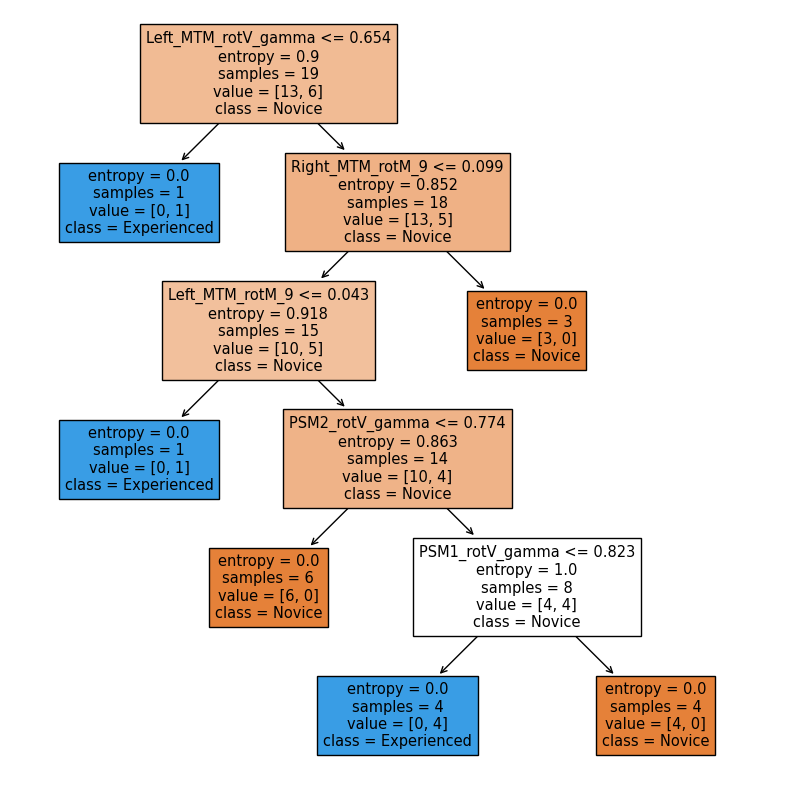

In [34]:
#Visualizing the Decision Tree model
#Decision_tree_visualization(class_names, model, feature_names, fig_size)
    #class names should be in ascending order: 0,1,2,3...
    #0-Novice, 1-Experienced --> Novice, Experienced
pm.Decision_tree_visualization(["Novice", "Experienced"], DT_model_ApEn_binary, feature_names, (10,10))

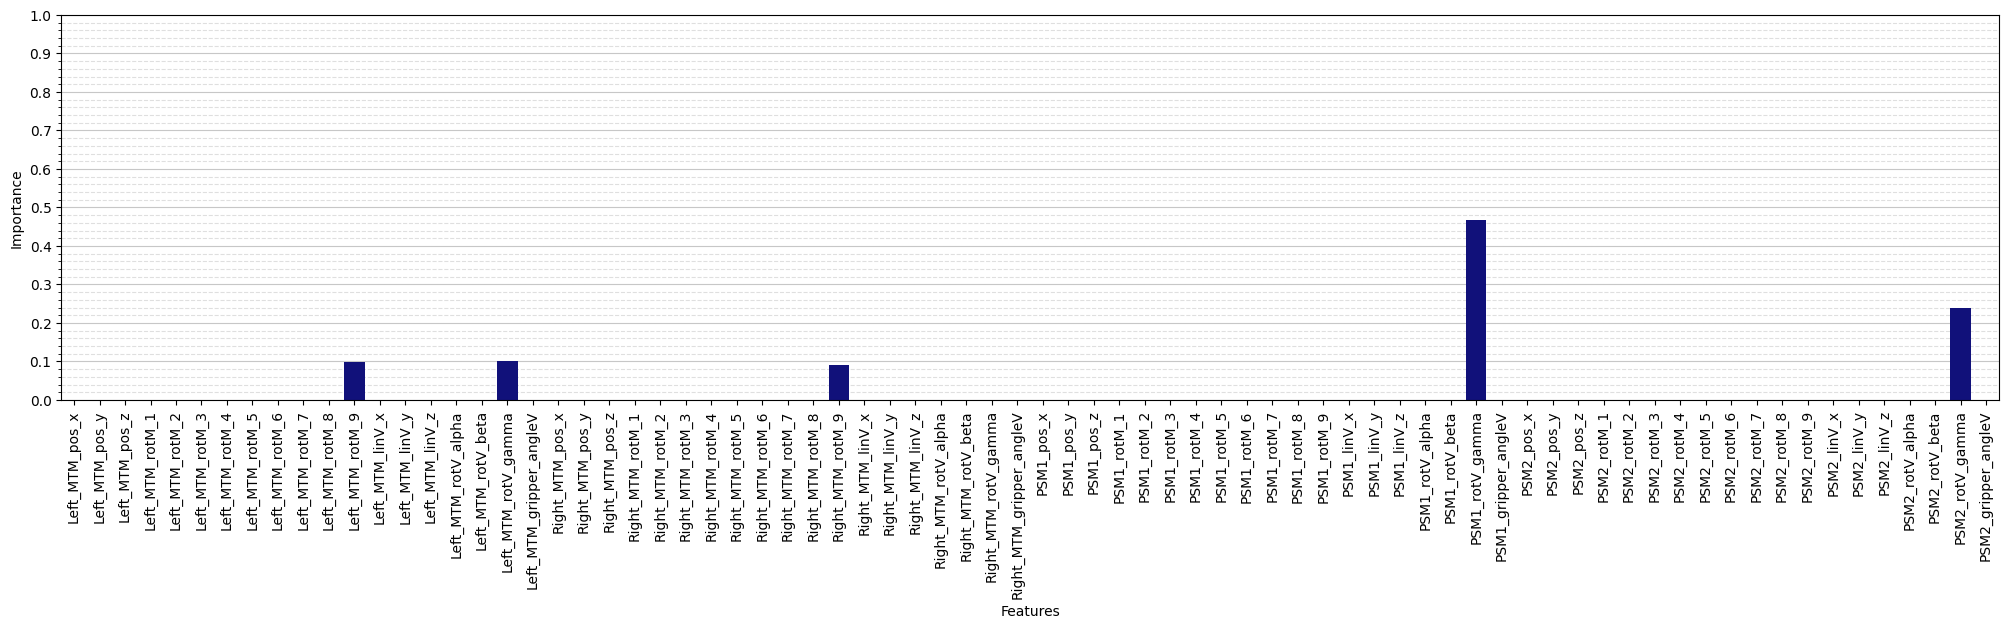

In [35]:
#Calculating the features importance of the DT model
#Decision_tree_feature_importance(model, features, bar_color, fig_size, sort, only_not_null, vertical)
pm.Decision_tree_feature_importance(DT_model_ApEn_binary, feature_names, "darkblue", (25,5), False, False, True)

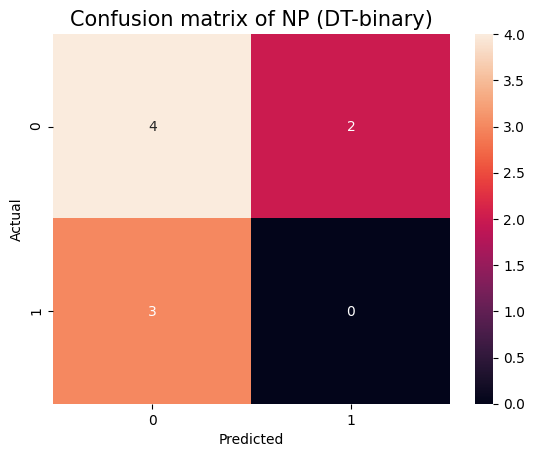

In [36]:
#Plotting the confusion matrix
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of NP (DT-binary)", DT_model_ApEn_binary, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

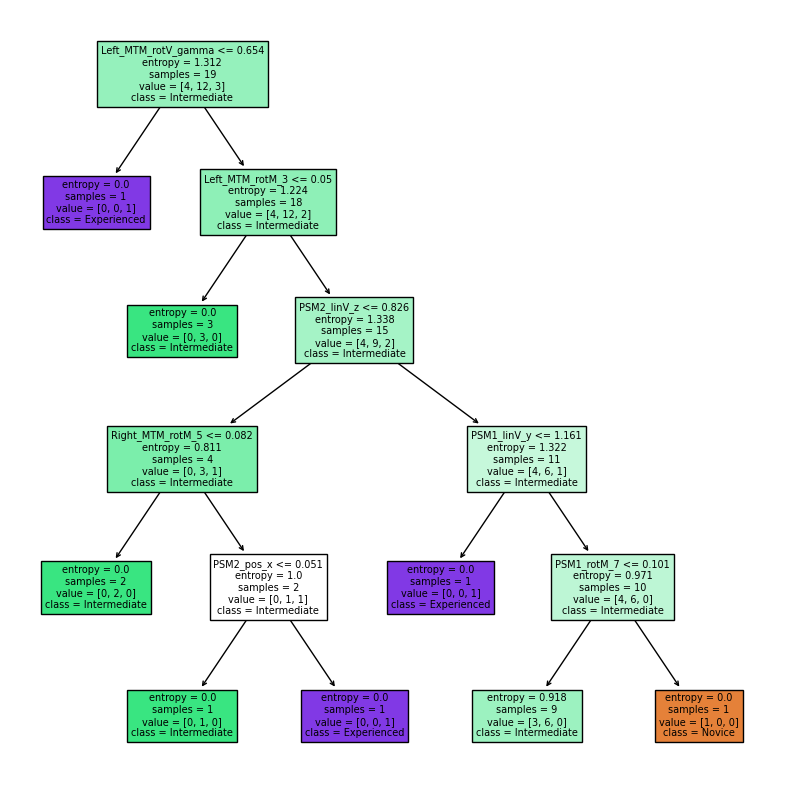

In [38]:
pm.Decision_tree_visualization(["Novice", "Intermediate", "Experienced"], DT_model_ApEn_multi, feature_names, (10,10))

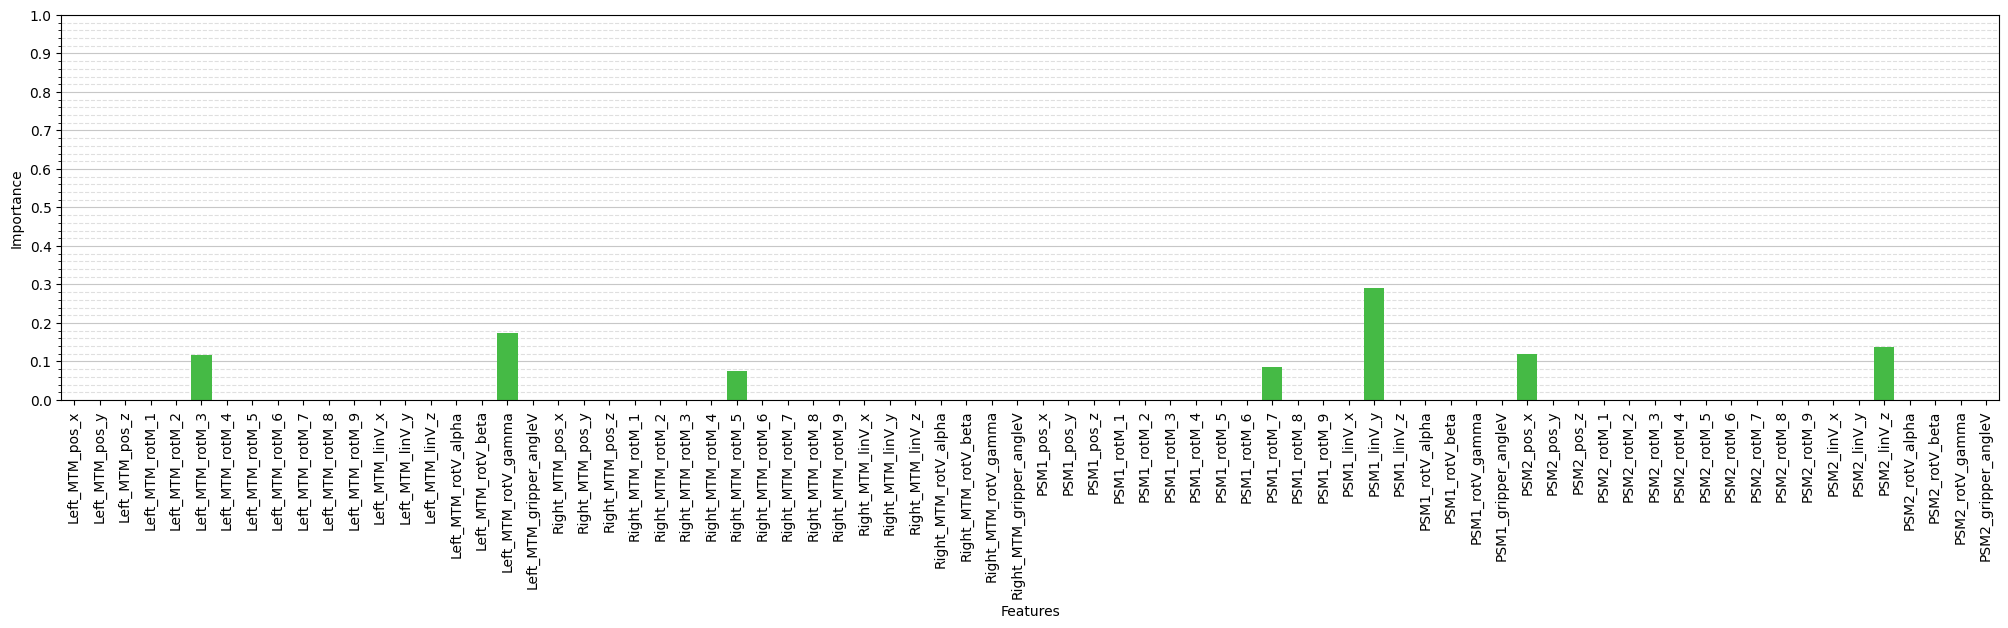

In [39]:
pm.Decision_tree_feature_importance(DT_model_ApEn_multi, feature_names, "limegreen", (25,5), False, False, True)

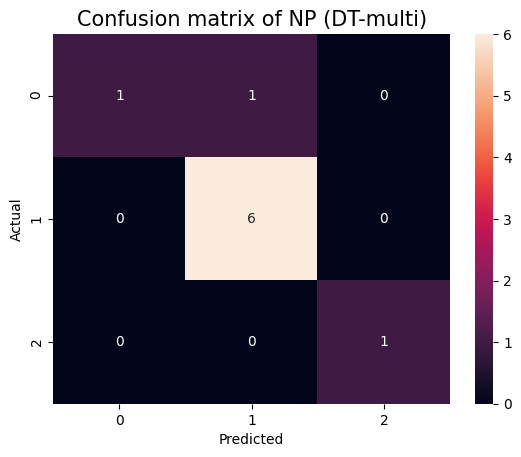

In [40]:
pm.Confusion_matrix("Confusion matrix of NP (DT-multi)", DT_model_ApEn_multi, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi)

### 5.4. Cross-validation

The Cross-Validation function should be applied only on the training data. This method provides a more robust approach to dataset splitting compared to a simple train/test split, as it does not rely on a single predefined split ratio for training and testing.

In k-fold cross-validation, the training data is divided into 𝑘 groups (or folds). For each iteration, k−1 folds are used as the training set, and the remaining fold serves as the validation set for evaluating model performance. This process is repeated k times (equal to the number of folds), ensuring that each group is used as the validation set exactly once. For instance, in a 3-fold cross-validation (illustrated in the figure), there will be three iterations, each with a different fold serving as the validation set. After completing all iterations, the performance from each fold are averaged to produce the final evaluation result.

<img src="images/Cross-validation.png" alt="Cross-validation" title="Cross-validation" width="700" height = "700"/>

Another type of cross-validation implemented in SCARS is Leave-One-Out Cross-Validation (LOOCV). Unlike k-fold cross-validation, LOOCV does not divide the dataset into multiple groups. Instead, a single data point is selected as the validation set, while the remaining data points are used as the training set. The number of iterations in LOOCV equals the total number of data points in the dataset, as each data point is used exactly once as the validation set. After running all of the iterations, the final result is obtained by averaging the performance from all iterations.

<img src="images/LOOCV.png" alt="LOOCV" title="LOOCV" width="700" height = "700"/>

In [37]:
#Calculating the accuracy with cross-validation
#Cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
NP_DT_model_3fold_ApEn = vrm.Cross_validation(DT_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, 3)
print(f"3-fold cross-validation: {NP_DT_model_3fold_ApEn}")

NP_DT_model_loocv_ApEn = vrm.Cross_validation(DT_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, "LOOCV")
print(f"LOOCV: {NP_DT_model_loocv_ApEn}")

3-fold cross-validation: 0.6746031746031745
LOOCV: 0.8421052631578947


In [38]:
#Explaning the cross-validation process
#Explained_cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
vrm.Explained_cross_validation(DT_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, 3)

Train: [ 7  8  9 10 11 12 13 14 15 16 17 18]  	 Validation: [0 1 2 3 4 5 6]
Train: [ 0  1  2  3  4  5  6 12 14 15 16 17 18]  	 Validation: [ 7  8  9 10 11 13]
Train: [ 0  1  2  3  4  5  6  7  8  9 10 11 13]  	 Validation: [12 14 15 16 17 18]

Accuracies: [0.8571428571428571, 0.6666666666666666, 0.5]
Mean accuracy: 0.6746031746031745


In [43]:
vrm.Explained_cross_validation(DT_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, "LOOCV")

Train: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [0]
Train: [ 0  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [1]
Train: [ 0  1  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [2]
Train: [ 0  1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [3]
Train: [ 0  1  2  3  5  6  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [4]
Train: [ 0  1  2  3  4  6  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [5]
Train: [ 0  1  2  3  4  5  7  8  9 10 11 12 13 14 15 16 17 18]   Validation: [6]
Train: [ 0  1  2  3  4  5  6  8  9 10 11 12 13 14 15 16 17 18]   Validation: [7]
Train: [ 0  1  2  3  4  5  6  7  9 10 11 12 13 14 15 16 17 18]   Validation: [8]
Train: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18]   Validation: [9]
Train: [ 0  1  2  3  4  5  6  7  8  9 11 12 13 14 15 16 17 18]   Validation: [10]
Train: [ 0  1  2  3  4  5  6  7  8  9 10 12 13 14 15 16 17 18]   Validation: [11]
Train: [ 0  1  2  3  4  5 

---
# 6. Logistic Regression

The Logistic Regression (LR) algorithm uses a logistic curve to perform classification. The model outputs probabilities that are mapped to either 0 or 1, as illustrated in the figure below. Classification is determined using a threshold value of 0.5. If the output probability exceeds 0.5, the data point is classified into the blue class. If the output probability is less than or equal to 0.5, the data point is classified into the orange class.

<center><img src="images/LR.png" alt="Logistic Regression" title="Logistic Regression" width="400" height = "400"/></center>

Various parameter values can be configured to optimize the performance. The possible values available for each parameter in SCARS are detailed in the table below.

### <center>Usable parameter values</center>

| Parameter names | Values                                           |
|-----------------|--------------------------------------------------|
| penalty         | “l1”, “l2”, None                                 |
| C               | float                                            |
| solver          | “lbfgs”, “liblinear”, “newton-cg”, “sag”, “saga” |
| max_iter        | int                                              |
| binary_class    | True, False                                      |

Not all combinations of solver and penalty parameter values are compatible. The possible valid pairs are summarized in the table below.

### <center>Solver-penalty pairs</center>

| Solver      | Penalty          |
|-------------|------------------|
| “lbfgs”     | “l2”, None       |
| “liblinear” | “l1”, “l2”       |
| “newton-cg” | “l2”, None       |
| “sag”       | “l2”, None       |
| “saga”      | “l1”, “l2”, None |

### 6.1. Model creation and traning-testing

In [39]:
#Logistic_regression(penalty, C, solver, max_iter, binary_class)
    #binary_class: True, False
        #True: Binary classification
        #False: Multi   
LogR_model_ApEn_binary = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, True)
LogR_model_ApEn_multi = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, False)
LogR_standardized_model_ApEn_binary = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, True)
LogR_standardized_model_ApEn_multi = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, False)

LogR_model_ApEn_binary

LogisticRegression(C=2.0, max_iter=5000, random_state=0, solver='newton-cg')

In [40]:
#Visualizing the classification report of the model
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(LogR_model_ApEn_binary, KT_X_train_ApEn, KT_X_test_ApEn, KT_Y_train_ApEn_binary, KT_Y_test_ApEn_binary)

Actual classes: [1 1 1 1 0 1 1 0 0 0 0], Predicted classes: [0 1 1 0 1 1 0 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.57      0.80      0.67         5
           1       0.75      0.50      0.60         6

    accuracy                           0.64        11
   macro avg       0.66      0.65      0.63        11
weighted avg       0.67      0.64      0.63        11



In [46]:
#Multiclass version
vrm.Model_classification_report(LogR_model_ApEn_multi, KT_X_train_ApEn, KT_X_test_ApEn, KT_Y_train_ApEn_multi, KT_Y_test_ApEn_multi)

Actual classes: [1 1 2 2 0 1 1 1 1 1 0], Predicted classes: [0 1 1 0 1 1 1 0 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.57      0.57      0.57         7
           2       0.00      0.00      0.00         2

    accuracy                           0.36        11
   macro avg       0.19      0.19      0.19        11
weighted avg       0.36      0.36      0.36        11



### 6.2. Results checking

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
#Checking the results
model = LogisticRegression(random_state = 0, penalty = "l2", C = 2.0, solver = "newton-cg", max_iter = 5000)
model.fit(KT_X_train_ApEn, KT_Y_train_ApEn_binary)
model.score(KT_X_test_ApEn, KT_Y_test_ApEn_binary)

0.6363636363636364

### 6.3. LR visualization

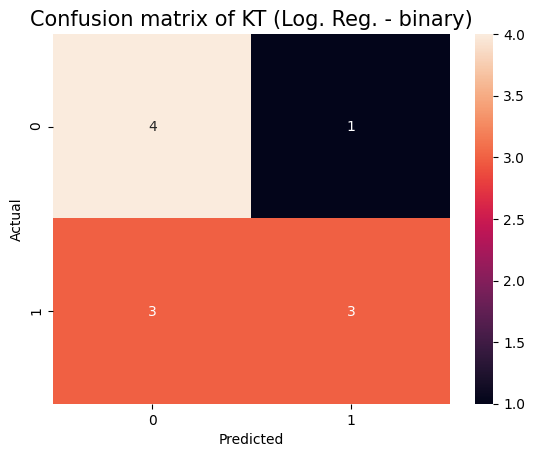

In [50]:
#Plotting the confusion matrix
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of KT (Log. Reg. - binary)", LogR_model_ApEn_binary, KT_X_train_ApEn, KT_X_test_ApEn, KT_Y_train_ApEn_binary, KT_Y_test_ApEn_binary)

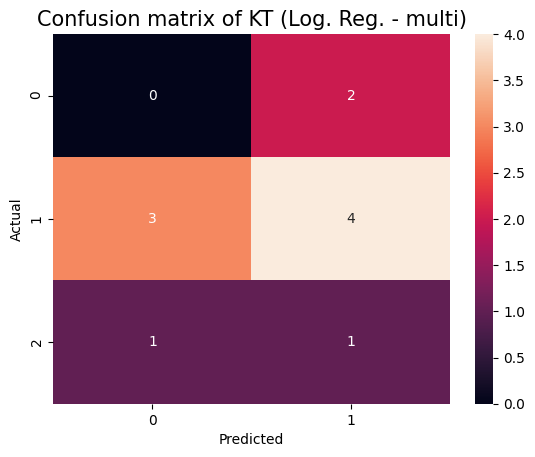

In [51]:
pm.Confusion_matrix("Confusion matrix of KT (Log. Reg. - multi)", LogR_model_ApEn_multi, KT_X_train_ApEn, KT_X_test_ApEn, KT_Y_train_ApEn_multi, KT_Y_test_ApEn_multi)

### 6.4. Cross-validation

In [52]:
KT_LR_model_3fold_ApEn = vrm.Cross_validation(LogR_model_ApEn_binary, KT_X_train_ApEn, KT_Y_train_ApEn_binary, 3)
print("3-fold cross-validation: %s" %(KT_LR_model_3fold_ApEn))

KT_LR_model_loocv_ApEn = vrm.Cross_validation(LogR_model_ApEn_binary, KT_X_train_ApEn, KT_Y_train_ApEn_binary, "LOOCV")
print("LOOCV: %s" %(KT_LR_model_loocv_ApEn))

3-fold cross-validation: 0.7546296296296297
LOOCV: 0.76


---
# 7. k-NN
The k-Nearest Neighbors (k-NN) algorithm classifies data points based on the classes of their nearest neighbors. The parameter 𝑘 determines the number of neighbors considered when assigning a class to a new data point (represented as a white diamond in the picture below). In the image, two scenarios are presented: one with 𝑘 = 3 and another with 𝑘 = 6. If the k is three the algorithm examines the 3 closest neighbors to determine the class of the diamond. Within the 𝑘 = 3 circle, there are 2 orange neighbors and 1 blue neighbor. Since orange is the majority, the diamond is classified as orange. For 𝑘 = 6 the algorithm expands its consideration to the 6 nearest neighbors. Within the 𝑘 = 6 circle, blue neighbors are in the majority, so the diamond is classified as blue.

<center><img src="images/kNN.png" alt="k-nearest neighbors" title="k-nearest neighbors" width="400" height = "400"/></center>

Various parameter values can be configured to optimize the performance. The possible values available for each parameter in SCARS are detailed in the table below.

### <center>Usable parameter values</center>

| Parameter names | Values                                |
|-----------------|---------------------------------------|
| n_neighbors     | int                                   |
| weights         | “uniform”, “distance”                 |
| metric          | “euclidean”, “manhattan”, “minkowski” |

### 7.1. Model creation and traning-testing

In [41]:
#kNN(n_neighbors, weights, metric)
kNN_model_ApEn_binary = nts_cam.kNN(1, "distance", "euclidean")
kNN_model_ApEn_multi = nts_cam.kNN(1, "distance", "euclidean")
kNN_standardized_model_ApEn_binary = nts_cam.kNN(1, "distance", "euclidean")
kNN_standardized_model_ApEn_multi = nts_cam.kNN(1, "distance", "euclidean")

kNN_model_ApEn_binary

KNeighborsClassifier(metric='euclidean', n_neighbors=1, weights='distance')

In [42]:
#Visualizing the classification report of the model
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(kNN_model_ApEn_binary, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [0 1 0 0 0 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.75      1.00      0.86         6
           1       1.00      0.33      0.50         3

    accuracy                           0.78         9
   macro avg       0.88      0.67      0.68         9
weighted avg       0.83      0.78      0.74         9



In [55]:
#Multiclass version
vrm.Model_classification_report(kNN_model_ApEn_multi, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi)

Actual classes: [1 1 1 1 0 0 1 1 2], Predicted classes: [0 2 1 1 1 1 1 1 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.57      0.67      0.62         6
           2       0.00      0.00      0.00         1

    accuracy                           0.44         9
   macro avg       0.19      0.22      0.21         9
weighted avg       0.38      0.44      0.41         9



### 7.2. Results checking

In [56]:
from sklearn.neighbors import KNeighborsClassifier

In [57]:
#Checking the results
model = KNeighborsClassifier(metric="euclidean", n_neighbors=1, weights="distance")
model.fit(NP_X_train_ApEn, NP_Y_train_ApEn_binary)
model.score(NP_X_test_ApEn, NP_Y_test_ApEn_binary)

0.7777777777777778

### 7.3. k-NN visualization

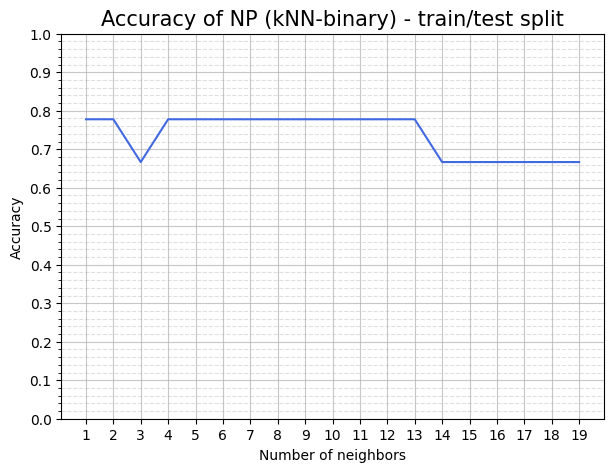

In [43]:
#Investigating the accuracy with different numbers of neighbors
#kNN_k_values_plot(model, title, color, method, metric, metric_type, X_train, X_test, Y_train, Y_test, fig_size)
    #method: "train/test", "LOOCV", int for k-fold
    #metric: "accuracy", "precision", "recall", "f1-score"
    #metric_type: None, "macro", "weighted"
        #accuracy: None
        #precision, recall, f1-score: "macro", "weighted"
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Accuracy of NP (kNN-binary) - train/test split", "royalblue", "train/test", "accuracy", None, \
                     NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary, (7,5))

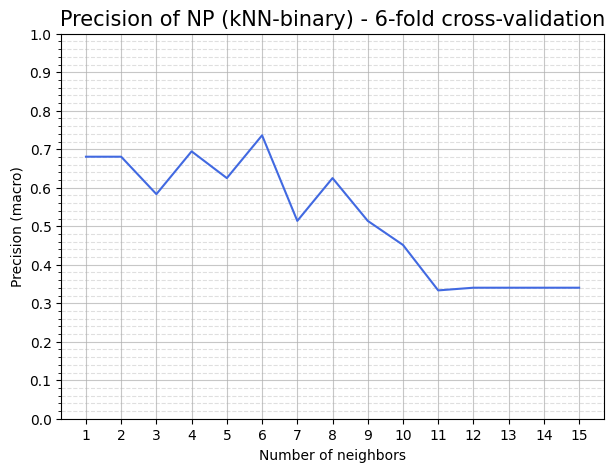

In [59]:
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Precision of NP (kNN-binary) - 6-fold cross-validation", "royalblue", 6, "precision", "macro", \
                     NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary, (7,5))

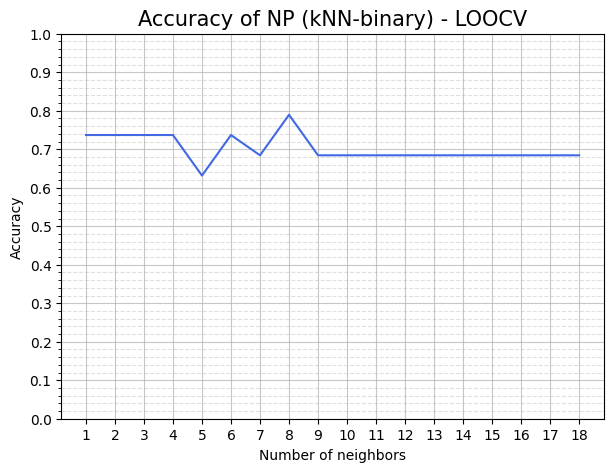

In [60]:
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Accuracy of NP (kNN-binary) - LOOCV", "royalblue", "LOOCV", "accuracy", None, \
                     NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary, (7,5))

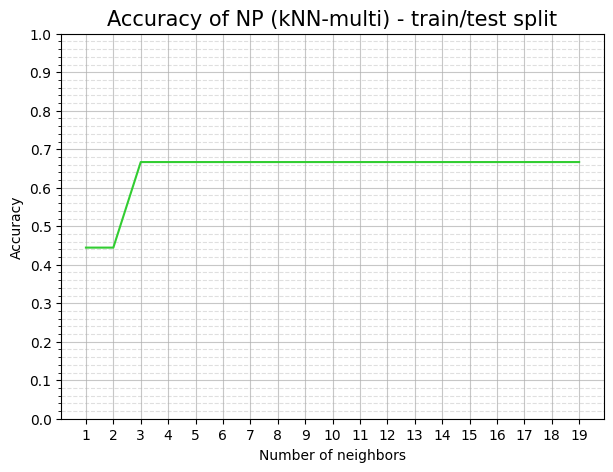

In [61]:
#Multiclass
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Accuracy of NP (kNN-multi) - train/test split", "limegreen", "train/test", "accuracy", None, \
                     NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi, (7,5))

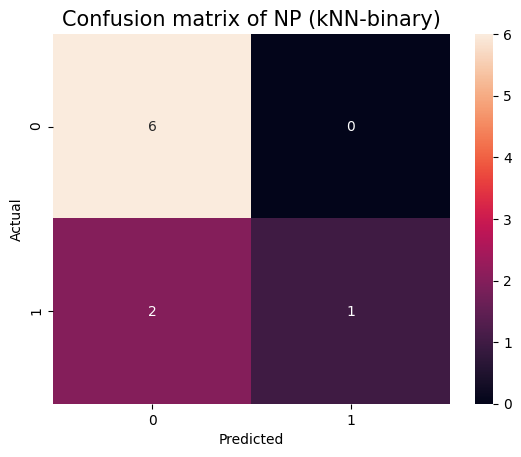

In [62]:
#Plotting the confusion matrix
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of NP (kNN-binary)", kNN_model_ApEn_binary, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

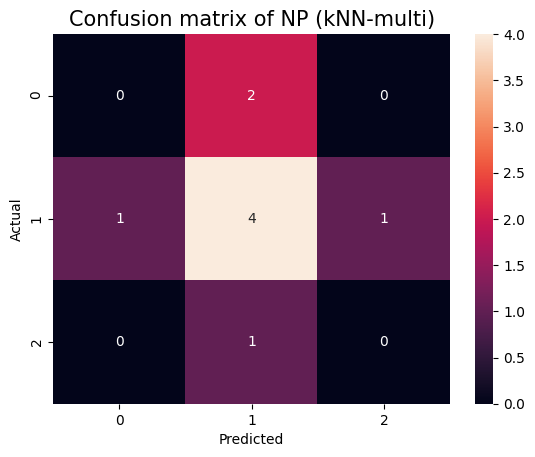

In [63]:
#Multiclass version
pm.Confusion_matrix("Confusion matrix of NP (kNN-multi)", kNN_model_ApEn_multi, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi)

### 7.4. Cross-validation

In [64]:
NP_kNN_model_3fold_ApEn = vrm.Cross_validation(kNN_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, 3)
print("3-fold cross-validation: %s" %(NP_kNN_model_3fold_ApEn))

NP_kNN_model_loocv_ApEn = vrm.Cross_validation(kNN_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, "LOOCV")
print("LOOCV: %s" %(NP_kNN_model_loocv_ApEn))

3-fold cross-validation: 0.8412698412698413
LOOCV: 0.7368421052631579


---
# 8. SVM
The purpose of the Support Vector Machine (SVM) algorithm is to identify the maximum margin hyperplane that best separates the classes in the dataset. The points closest to the margin, known as support vectors (marked with green circles in the figure below), define the margin width. The margin can be adjusted by tuning the C and gamma parameters.

<center><img src="images/SVM.png" alt="Support Vector Machine" title="Support Vector Machine" width="400" height = "400"/></center>

Various parameter values can be configured to optimize the performance. The possible values available for each parameter in SCARS are detailed in the table below.

### <center>Usable parameter values</center>

| Parameter names | Values                             |
|-----------------|------------------------------------|
| C               | float                              |
| kernel          | “linear”, “poly”, “rbf”, “sigmoid” |
| gamma           | “scale”, “auto”, float             |
| binary_class    | True, False                        |

### 8.1. Model creation and traning-testing

In [44]:
#SVM(C, kernel, gamma, binary_class)
    #binary_class: True, False
        #True: binary classification
        #False: multiclass classification
        
SVM_model_ApEn_binary = nts_cam.SVM(2.0, "poly", 1.0, True)
SVM_model_ApEn_multi = nts_cam.SVM(2.0, "poly", 1.0, False)
SVM_standardized_model_ApEn_binary = nts_cam.SVM(2.0, "poly", 1.0, True)
SVM_standardized_model_ApEn_multi = nts_cam.SVM(2.0, "poly", 1.0, False)

SVM_model_ApEn_binary

SVC(C=2.0, gamma=1.0, kernel='poly', random_state=0)

In [45]:
#Visualizing the classification report of the model
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(SVM_model_ApEn_binary, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [0 1 0 0 0 0 0 1 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.71      0.83      0.77         6
           1       0.50      0.33      0.40         3

    accuracy                           0.67         9
   macro avg       0.61      0.58      0.58         9
weighted avg       0.64      0.67      0.65         9



In [67]:
#Multiclass version
vrm.Model_classification_report(SVM_model_ApEn_multi, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi)

Actual classes: [1 1 1 1 0 0 1 1 2], Predicted classes: [0 2 1 1 1 1 1 2 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.50      0.50      0.50         6
           2       0.00      0.00      0.00         1

    accuracy                           0.33         9
   macro avg       0.17      0.17      0.17         9
weighted avg       0.33      0.33      0.33         9



### 8.2. Results checking

In [68]:
from sklearn import svm

In [69]:
#Checking the results
model = svm.SVC(C=2.0, gamma=1.0, kernel="poly", random_state=0)
model.fit(NP_X_train_ApEn, NP_Y_train_ApEn_binary)
model.score(NP_X_test_ApEn, NP_Y_test_ApEn_binary)

0.6666666666666666

### 8.3. SVM visualization

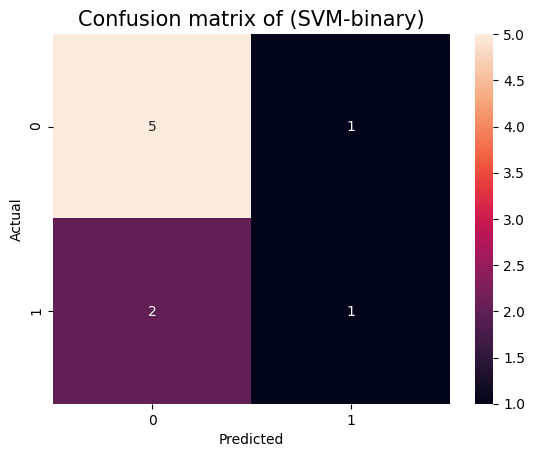

In [70]:
#Plotting the confusion matrix
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of (SVM-binary)", SVM_model_ApEn_binary, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_binary, NP_Y_test_ApEn_binary)

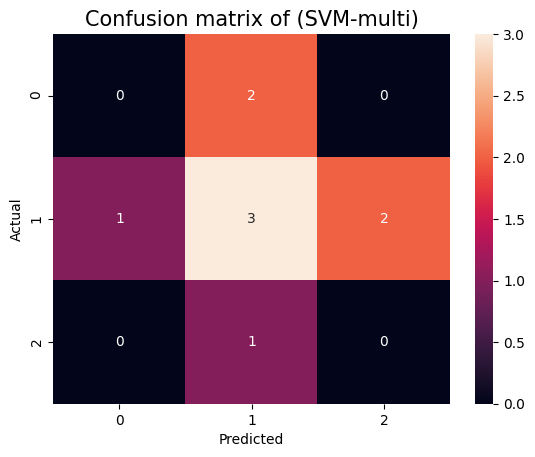

In [71]:
pm.Confusion_matrix("Confusion matrix of (SVM-multi)", SVM_model_ApEn_multi, NP_X_train_ApEn, NP_X_test_ApEn, NP_Y_train_ApEn_multi, NP_Y_test_ApEn_multi)

### 8.4. Cross-validation

In [72]:
NP_SVM_model_3fold_ApEn = vrm.Cross_validation(SVM_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, 3)
print("3-fold cross-validation: %s" %(NP_SVM_model_3fold_ApEn))

NP_SVM_model_loocv_ApEn = vrm.Cross_validation(SVM_model_ApEn_binary, NP_X_train_ApEn, NP_Y_train_ApEn_binary, "LOOCV")
print("LOOCV: %s" %(NP_SVM_model_loocv_ApEn))

3-fold cross-validation: 0.7380952380952381
LOOCV: 0.8421052631578947


---
# 9. Time series classification: k-NN with DTW
### 9.1. Data transformation

In [17]:
NP_df_list[0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.118529,-0.015860,0.367277,0.482652,-0.326916,-0.812538,0.642312,0.762788,0.074571,0.594823,...,-0.583559,0.578939,0.569462,-0.013975,-0.002687,0.006508,-0.021289,-0.230186,0.452584,-1.198475
1,0.117837,-0.016283,0.367878,0.470070,-0.331100,-0.818200,0.649242,0.757665,0.066332,0.597381,...,-0.585849,0.583027,0.562902,-0.006929,-0.003082,0.006237,-0.019702,-0.142757,0.343896,-1.202884
2,0.117591,-0.016579,0.368282,0.464992,-0.333945,-0.819944,0.652489,0.755208,0.062384,0.597824,...,-0.586203,0.584588,0.560911,-0.007013,-0.007571,0.011385,-0.058685,-0.138019,0.321906,-1.201741
3,0.117164,-0.017204,0.369130,0.457999,-0.337982,-0.822223,0.657503,0.751245,0.057376,0.597736,...,-0.586036,0.587470,0.558068,-0.000156,-0.008891,0.010383,-0.064197,-0.068266,0.171226,-1.198312
4,0.116830,-0.017850,0.369779,0.457318,-0.342555,-0.820707,0.656666,0.752381,0.051810,0.599175,...,-0.587479,0.583116,0.561108,-0.000627,-0.011057,0.008655,-0.058588,0.077483,-0.011222,-1.195536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3433,0.142431,-0.019635,0.426738,0.857629,-0.247396,-0.450902,0.299046,0.953128,0.045724,0.417392,...,-0.417144,0.192595,0.888198,-0.000274,-0.002466,-0.001380,-2.250799,1.036829,4.962650,-0.540414
3434,0.142378,-0.019676,0.426621,0.861480,-0.264215,-0.433691,0.312973,0.948748,0.043565,0.398884,...,-0.397702,0.195262,0.896495,-0.000363,0.001951,-0.006721,0.063972,0.508576,-0.221638,-0.391330
3435,0.142191,-0.019512,0.425955,0.863868,-0.297715,-0.406378,0.342397,0.938687,0.040040,0.368470,...,-0.365923,0.194084,0.910181,-0.000650,-0.000191,-0.007957,0.166514,0.675894,-0.078584,-0.081241
3436,0.142137,-0.019330,0.425178,0.871721,-0.299333,-0.388004,0.338906,0.940116,0.036006,0.352910,...,-0.350691,0.183105,0.918415,-0.000539,0.005146,-0.012726,0.200262,0.397835,-0.071289,0.174962


In [18]:
#Matching the length of all time series data by appending each series to match the length of the longest series.
#TS_df_append_to_max_len(df_list, feature_names)
TS_NP_df_list_max_len = dmm.TS_df_append_to_max_len(NP_df_list, feature_names)
TS_KT_df_list_max_len = dmm.TS_df_append_to_max_len(KT_df_list, feature_names)
TS_SU_df_list_max_len = dmm.TS_df_append_to_max_len(SU_df_list, feature_names)

#Matching the length of all time series data by appending each series to match the length of the average length.
#TS_df_append_truncate_to_avg_len(df_list, feature_names)
TS_NP_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(NP_df_list, feature_names)
TS_KT_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(KT_df_list, feature_names)
TS_SU_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(SU_df_list, feature_names)

#Matching the length of all time series data by appending each series to match the length of the shortest series.
#TS_df_truncate_to_min_len(df_list)
TS_NP_df_list_min_len = dmm.TS_df_truncate_to_min_len(NP_df_list)
TS_KT_df_list_min_len = dmm.TS_df_truncate_to_min_len(KT_df_list)
TS_SU_df_list_min_len = dmm.TS_df_truncate_to_min_len(SU_df_list)

The maximum length: 4761
The maximum length: 3853
The maximum length: 9012
The average length: 3245
The average length: 1725
The average length: 3369
The minimum length: 1787
The minimum length: 920
The minimum length: 1779


In [19]:
TS_NP_df_list_min_len[0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.118529,-0.015860,0.367277,0.482652,-0.326916,-0.812538,0.642312,0.762788,0.074571,0.594823,...,-0.583559,0.578939,0.569462,-0.013975,-0.002687,0.006508,-0.021289,-0.230186,0.452584,-1.198475
1,0.117837,-0.016283,0.367878,0.470070,-0.331100,-0.818200,0.649242,0.757665,0.066332,0.597381,...,-0.585849,0.583027,0.562902,-0.006929,-0.003082,0.006237,-0.019702,-0.142757,0.343896,-1.202884
2,0.117591,-0.016579,0.368282,0.464992,-0.333945,-0.819944,0.652489,0.755208,0.062384,0.597824,...,-0.586203,0.584588,0.560911,-0.007013,-0.007571,0.011385,-0.058685,-0.138019,0.321906,-1.201741
3,0.117164,-0.017204,0.369130,0.457999,-0.337982,-0.822223,0.657503,0.751245,0.057376,0.597736,...,-0.586036,0.587470,0.558068,-0.000156,-0.008891,0.010383,-0.064197,-0.068266,0.171226,-1.198312
4,0.116830,-0.017850,0.369779,0.457318,-0.342555,-0.820707,0.656666,0.752381,0.051810,0.599175,...,-0.587479,0.583116,0.561108,-0.000627,-0.011057,0.008655,-0.058588,0.077483,-0.011222,-1.195536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1782,0.043665,0.016416,0.343835,0.675191,-0.673479,-0.300978,0.685839,0.422797,0.592317,-0.272497,...,0.284690,0.610141,0.739377,0.000263,0.007723,-0.011261,0.084754,-0.030775,0.034461,0.471498
1783,0.043771,0.016523,0.343137,0.666254,-0.681361,-0.303146,0.691098,0.411283,0.594309,-0.281086,...,0.292138,0.609575,0.736934,-0.001335,0.000736,-0.008763,-1.632478,3.177223,4.251943,0.505952
1784,0.043899,0.016377,0.342734,0.667758,-0.679424,-0.304185,0.689999,0.411490,0.595440,-0.280214,...,0.292424,0.611041,0.735605,-0.002304,-0.001303,-0.010390,0.011727,-0.057290,-0.048266,0.510687
1785,0.044084,0.015875,0.341937,0.669127,-0.677485,-0.305496,0.689118,0.411619,0.596371,-0.279113,...,0.291224,0.613136,0.734338,0.003767,-0.004554,-0.012807,0.050068,-0.103899,0.161996,0.513790


In [20]:
#Selecting the target variable
#TS_Y(df_class, column_index)
TS_NP_Y_binary = dmm.TS_Y(NP_class_binary, 2)
TS_KT_Y_binary = dmm.TS_Y(KT_class_binary, 2)
TS_SU_Y_binary = dmm.TS_Y(SU_class_binary, 2)

In [21]:
#Multiclass version
TS_NP_Y_multi = dmm.TS_Y(NP_class_multi, 2)
TS_KT_Y_multi = dmm.TS_Y(KT_class_multi, 2)
TS_SU_Y_multi = dmm.TS_Y(SU_class_multi, 2)

### 9.2. Train-test split

In [22]:
#Train-test split
TS_NP_X_train_max_len, TS_NP_X_test_max_len, TS_NP_Y_train_max_len_binary, TS_NP_Y_test_max_len_binary = dmm.Train_test(TS_NP_df_list_max_len, TS_NP_Y_binary, 0.3)
TS_KT_X_train_max_len, TS_KT_X_test_max_len, TS_KT_Y_train_max_len_binary, TS_KT_Y_test_max_len_binary = dmm.Train_test(TS_KT_df_list_max_len, TS_KT_Y_binary, 0.3)
TS_SU_X_train_max_len, TS_SU_X_test_max_len, TS_SU_Y_train_max_len_binary, TS_SU_Y_test_max_len_binary = dmm.Train_test(TS_SU_df_list_max_len, TS_SU_Y_binary, 0.3)

TS_NP_X_train_avg_len, TS_NP_X_test_avg_len, TS_NP_Y_train_avg_len_binary, TS_NP_Y_test_avg_len_binary = dmm.Train_test(TS_NP_df_list_avg_len, TS_NP_Y_binary, 0.3)
TS_KT_X_train_avg_len, TS_KT_X_test_avg_len, TS_KT_Y_train_avg_len_binary, TS_KT_Y_test_avg_len_binary = dmm.Train_test(TS_KT_df_list_avg_len, TS_KT_Y_binary, 0.3)
TS_SU_X_train_avg_len, TS_SU_X_test_avg_len, TS_SU_Y_train_avg_len_binary, TS_SU_Y_test_avg_len_binary = dmm.Train_test(TS_SU_df_list_avg_len, TS_SU_Y_binary, 0.3)

TS_NP_X_train_min_len, TS_NP_X_test_min_len, TS_NP_Y_train_min_len_binary, TS_NP_Y_test_min_len_binary = dmm.Train_test(TS_NP_df_list_min_len, TS_NP_Y_binary, 0.3)
TS_KT_X_train_min_len, TS_KT_X_test_min_len, TS_KT_Y_train_min_len_binary, TS_KT_Y_test_min_len_binary = dmm.Train_test(TS_KT_df_list_min_len, TS_KT_Y_binary, 0.3)
TS_SU_X_train_min_len, TS_SU_X_test_min_len, TS_SU_Y_train_min_len_binary, TS_SU_Y_test_min_len_binary = dmm.Train_test(TS_SU_df_list_min_len, TS_SU_Y_binary, 0.3)

In [23]:
#Multiclass verison
TS_NP_X_train_max_len, TS_NP_X_test_max_len, TS_NP_Y_train_max_len_multi, TS_NP_Y_test_max_len_multi = dmm.Train_test(TS_NP_df_list_max_len, TS_NP_Y_multi, 0.3)
TS_KT_X_train_max_len, TS_KT_X_test_max_len, TS_KT_Y_train_max_len_multi, TS_KT_Y_test_max_len_multi = dmm.Train_test(TS_KT_df_list_max_len, TS_KT_Y_multi, 0.3)
TS_SU_X_train_max_len, TS_SU_X_test_max_len, TS_SU_Y_train_max_len_multi, TS_SU_Y_test_max_len_multi = dmm.Train_test(TS_SU_df_list_max_len, TS_SU_Y_multi, 0.3)

TS_NP_X_train_avg_len, TS_NP_X_test_avg_len, TS_NP_Y_train_avg_len_multi, TS_NP_Y_test_avg_len_multi = dmm.Train_test(TS_NP_df_list_avg_len, TS_NP_Y_multi, 0.3)
TS_KT_X_train_avg_len, TS_KT_X_test_avg_len, TS_KT_Y_train_avg_len_multi, TS_KT_Y_test_avg_len_multi = dmm.Train_test(TS_KT_df_list_avg_len, TS_KT_Y_multi, 0.3)
TS_SU_X_train_avg_len, TS_SU_X_test_avg_len, TS_SU_Y_train_avg_len_multi, TS_SU_Y_test_avg_len_multi = dmm.Train_test(TS_SU_df_list_avg_len, TS_SU_Y_multi, 0.3)

TS_NP_X_train_min_len, TS_NP_X_test_min_len, TS_NP_Y_train_min_len_multi, TS_NP_Y_test_min_len_multi = dmm.Train_test(TS_NP_df_list_min_len, TS_NP_Y_multi, 0.3)
TS_KT_X_train_min_len, TS_KT_X_test_min_len, TS_KT_Y_train_min_len_multi, TS_KT_Y_test_min_len_multi = dmm.Train_test(TS_KT_df_list_min_len, TS_KT_Y_multi, 0.3)
TS_SU_X_train_min_len, TS_SU_X_test_min_len, TS_SU_Y_train_min_len_multi, TS_SU_Y_test_min_len_multi = dmm.Train_test(TS_SU_df_list_min_len, TS_SU_Y_multi, 0.3)

### 9.3. Standardization

In [24]:
#TS_Standardization(X_train, X_test, feature_names)
TS_NP_standardized_X_train_max_len, TS_NP_standardized_X_test_max_len = dmm.TS_Standardization(TS_NP_X_train_max_len, TS_NP_X_test_max_len, feature_names)
TS_KT_standardized_X_train_max_len, TS_KT_standardized_X_test_max_len = dmm.TS_Standardization(TS_KT_X_train_max_len, TS_KT_X_test_max_len, feature_names)
TS_SU_standardized_X_train_max_len, TS_SU_standardized_X_test_max_len = dmm.TS_Standardization(TS_SU_X_train_max_len, TS_SU_X_test_max_len, feature_names)

TS_NP_standardized_X_train_avg_len, TS_NP_standardized_X_test_avg_len = dmm.TS_Standardization(TS_NP_X_train_avg_len, TS_NP_X_test_avg_len, feature_names)
TS_KT_standardized_X_train_avg_len, TS_KT_standardized_X_test_avg_len = dmm.TS_Standardization(TS_KT_X_train_avg_len, TS_KT_X_test_avg_len, feature_names)
TS_SU_standardized_X_train_avg_len, TS_SU_standardized_X_test_avg_len = dmm.TS_Standardization(TS_SU_X_train_avg_len, TS_SU_X_test_avg_len, feature_names)

TS_NP_standardized_X_train_min_len, TS_NP_standardized_X_test_min_len = dmm.TS_Standardization(TS_NP_X_train_min_len, TS_NP_X_test_min_len, feature_names)
TS_KT_standardized_X_train_min_len, TS_KT_standardized_X_test_min_len = dmm.TS_Standardization(TS_KT_X_train_min_len, TS_KT_X_test_min_len, feature_names)
TS_SU_standardized_X_train_min_len, TS_SU_standardized_X_test_min_len = dmm.TS_Standardization(TS_SU_X_train_min_len, TS_SU_X_test_min_len, feature_names)

### 9.4. Model creation and traning-testing

Various parameter values can be configured to optimize the performance. The possible values available for each parameter in SCARS are detailed in the table below.

### <center>Usable parameter values</center>

| Parameter names | Values                |
|-----------------|-----------------------|
| n_neighbors     | int                   |
| weights         | “uniform”, “distance” |

In [81]:
TS_NP_X_train_max_len[0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.200798,0.010260,0.432265,-0.758251,0.352502,-0.548491,-0.474116,-0.875559,0.092636,-0.446644,...,-0.419415,0.225198,0.879417,0.000005,-0.000006,-0.000003,0.000031,0.000033,0.000019,-0.840312
1,0.200807,0.010260,0.432265,-0.758058,0.352731,-0.548610,-0.474343,-0.875455,0.092462,-0.446731,...,-0.419505,0.225233,0.879366,0.000005,-0.000005,-0.000004,0.000032,0.000017,0.000018,-0.839333
2,0.200807,0.010260,0.432265,-0.757881,0.352946,-0.548717,-0.474553,-0.875358,0.092301,-0.446809,...,-0.419585,0.225264,0.879319,0.000004,-0.000005,-0.000003,0.000032,0.000015,0.000017,-0.839333
3,0.200798,0.010260,0.432265,-0.757808,0.353037,-0.548760,-0.474641,-0.875317,0.092234,-0.446840,...,-0.419617,0.225276,0.879301,0.000004,-0.000005,-0.000002,0.005064,-0.065294,0.187811,-0.838843
4,0.200799,0.010253,0.432273,-0.757640,0.353239,-0.548862,-0.474851,-0.875217,0.092104,-0.446902,...,-0.419682,0.225329,0.879256,0.000004,-0.000004,-0.000002,0.000034,0.000016,0.000017,-0.839169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4756,0.198258,0.009036,0.412213,-0.646886,0.404749,-0.646345,-0.541005,-0.840872,0.014811,-0.536700,...,-0.513460,0.259313,0.817994,0.012878,-0.005421,0.011624,0.179420,0.503470,0.665768,-0.880645
4757,0.198605,0.008943,0.412654,-0.647661,0.402873,-0.646740,-0.539298,-0.841955,0.015506,-0.537480,...,-0.512888,0.258944,0.818469,0.012702,-0.002525,0.013090,3.500782,-0.224972,-3.999643,-0.883094
4758,0.199659,0.009124,0.413532,-0.654023,0.395601,-0.644825,-0.534189,-0.845028,0.023301,-0.534869,...,-0.510948,0.258981,0.819670,0.012675,0.000021,0.014381,-0.063620,-0.029350,0.047334,-0.884891
4759,0.200834,0.009488,0.414473,-0.655709,0.392578,-0.644961,-0.531919,-0.846394,0.025514,-0.535065,...,-0.511259,0.259134,0.819428,0.012276,0.006958,0.010456,-0.032155,-0.043751,0.092371,-0.884891


In [82]:
#Transforming the shape of the time series data
#TS_kNN_DTW_transform(X_train, X_test)
TS_kNN_DTW_NP_X_train_max_len, TS_kNN_DTW_NP_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_NP_X_train_max_len, TS_NP_X_test_max_len)
TS_kNN_DTW_KT_X_train_max_len, TS_kNN_DTW_KT_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_KT_X_train_max_len, TS_KT_X_test_max_len)
TS_kNN_DTW_SU_X_train_max_len, TS_kNN_DTW_SU_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_SU_X_train_max_len, TS_SU_X_test_max_len)

TS_kNN_DTW_NP_X_train_avg_len, TS_kNN_DTW_NP_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_NP_X_train_avg_len, TS_NP_X_test_avg_len)
TS_kNN_DTW_KT_X_train_avg_len, TS_kNN_DTW_KT_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_KT_X_train_avg_len, TS_KT_X_test_avg_len)
TS_kNN_DTW_SU_X_train_avg_len, TS_kNN_DTW_SU_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_SU_X_train_avg_len, TS_SU_X_test_avg_len)

TS_kNN_DTW_NP_X_train_min_len, TS_kNN_DTW_NP_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_NP_X_train_min_len, TS_NP_X_test_min_len)
TS_kNN_DTW_KT_X_train_min_len, TS_kNN_DTW_KT_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_KT_X_train_min_len, TS_KT_X_test_min_len)
TS_kNN_DTW_SU_X_train_min_len, TS_kNN_DTW_SU_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_SU_X_train_min_len, TS_SU_X_test_min_len)

In [83]:
TS_kNN_DTW_NP_X_train_max_len[0]

array([[ 2.00798e-01,  2.00807e-01,  2.00807e-01, ...,  1.99659e-01,
         2.00834e-01,  2.02192e-01],
       [ 1.02600e-02,  1.02600e-02,  1.02600e-02, ...,  9.12400e-03,
         9.48800e-03,  9.66300e-03],
       [ 4.32265e-01,  4.32265e-01,  4.32265e-01, ...,  4.13532e-01,
         4.14473e-01,  4.15610e-01],
       ...,
       [ 3.30000e-05,  1.70000e-05,  1.50000e-05, ..., -2.93500e-02,
        -4.37510e-02, -1.20920e-01],
       [ 1.90000e-05,  1.80000e-05,  1.70000e-05, ...,  4.73340e-02,
         9.23710e-02,  1.06994e-01],
       [-8.40312e-01, -8.39333e-01, -8.39333e-01, ..., -8.84891e-01,
        -8.84891e-01, -8.85381e-01]])

In [84]:
TS_kNN_DTW_NP_X_train_max_len.shape

(19, 76, 4761)

In [85]:
#Standardized version
TS_kNN_DTW_NP_standardized_X_train_max_len, TS_kNN_DTW_NP_standardized_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_NP_standardized_X_train_max_len, TS_NP_standardized_X_test_max_len)
TS_kNN_DTW_KT_standardized_X_train_max_len, TS_kNN_DTW_KT_standardized_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_KT_standardized_X_train_max_len, TS_KT_standardized_X_test_max_len)
TS_kNN_DTW_SU_standardized_X_train_max_len, TS_kNN_DTW_SU_standardized_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_SU_standardized_X_train_max_len, TS_SU_standardized_X_test_max_len)

TS_kNN_DTW_NP_standardized_X_train_avg_len, TS_kNN_DTW_NP_standardized_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_NP_standardized_X_train_avg_len, TS_NP_standardized_X_test_avg_len)
TS_kNN_DTW_KT_standardized_X_train_avg_len, TS_kNN_DTW_KT_standardized_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_KT_standardized_X_train_avg_len, TS_KT_standardized_X_test_avg_len)
TS_kNN_DTW_SU_standardized_X_train_avg_len, TS_kNN_DTW_SU_standardized_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_SU_standardized_X_train_avg_len, TS_SU_standardized_X_test_avg_len)

TS_kNN_DTW_NP_standardized_X_train_min_len, TS_kNN_DTW_NP_standardized_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_NP_standardized_X_train_min_len, TS_NP_standardized_X_test_min_len)
TS_kNN_DTW_KT_standardized_X_train_min_len, TS_kNN_DTW_KT_standardized_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_KT_standardized_X_train_min_len, TS_KT_standardized_X_test_min_len)
TS_kNN_DTW_SU_standardized_X_train_min_len, TS_kNN_DTW_SU_standardized_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_SU_standardized_X_train_min_len, TS_SU_standardized_X_test_min_len)

In [51]:
from Modules import ts_classification_algorithms_module as ts_cam

In [52]:
#TS_kNN_DTW(n_neighbors, weights)
TS_kNN_DTW_model_binary = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_model_multi = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_standardized_model_binary = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_standardized_model_multi = ts_cam.TS_kNN_DTW(1, "uniform")

TS_kNN_DTW_model_binary

KNeighborsTimeSeriesClassifier()

In [53]:
#Sktime does not support unequal length time series
print(TS_kNN_DTW_model_binary.get_tags())

{'X_inner_mtype': 'numpy3D', 'capability:multivariate': True, 'capability:unequal_length': False, 'capability:missing_values': False, 'capability:train_estimate': False, 'capability:contractable': False, 'capability:multithreading': False, 'python_version': None, 'classifier_type': 'distance'}


In [89]:
vrm.Model_classification_report(TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_X_train_avg_len, TS_kNN_DTW_NP_X_test_avg_len, TS_NP_Y_train_avg_len_binary, TS_NP_Y_test_avg_len_binary)

Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [1 1 0 0 0 0 1 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.67      0.67         6
           1       0.33      0.33      0.33         3

    accuracy                           0.56         9
   macro avg       0.50      0.50      0.50         9
weighted avg       0.56      0.56      0.56         9



In [90]:
vrm.Model_classification_report(TS_kNN_DTW_model_multi, TS_kNN_DTW_NP_X_train_avg_len, TS_kNN_DTW_NP_X_test_avg_len, TS_NP_Y_train_avg_len_multi, TS_NP_Y_test_avg_len_multi)

Actual classes: [1 1 1 1 0 0 1 1 2], Predicted classes: [1 2 1 1 1 1 2 1 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.57      0.67      0.62         6
           2       0.00      0.00      0.00         1

    accuracy                           0.44         9
   macro avg       0.19      0.22      0.21         9
weighted avg       0.38      0.44      0.41         9



### 9.5. Results checking

In [92]:
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier

In [93]:
#Checking the results
model = KNeighborsTimeSeriesClassifier(n_neighbors = 1, weights =  "uniform")
model.fit(TS_kNN_DTW_NP_X_train_avg_len, TS_NP_Y_train_avg_len_binary)
model.score(TS_kNN_DTW_NP_X_test_avg_len, TS_NP_Y_test_avg_len_binary)

0.5555555555555556

### 9.6. Time series k-NN visualization

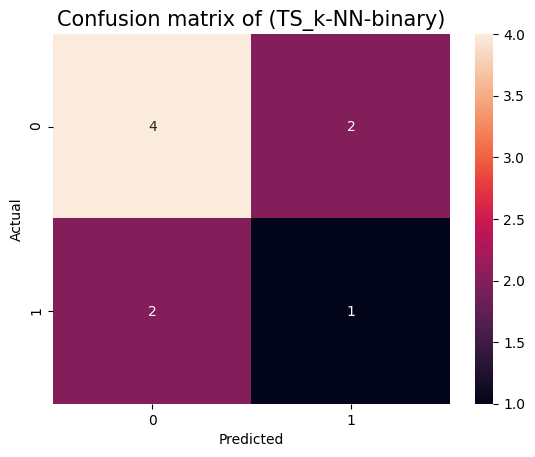

In [94]:
#Plotting the confusion matrix
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of (TS_k-NN-binary)", TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_X_train_avg_len, TS_kNN_DTW_NP_X_test_avg_len, TS_NP_Y_train_avg_len_binary, TS_NP_Y_test_avg_len_binary)

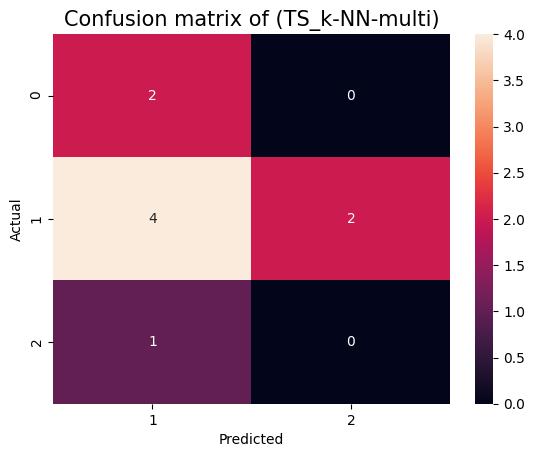

In [95]:
pm.Confusion_matrix("Confusion matrix of (TS_k-NN-multi)", TS_kNN_DTW_model_multi, TS_kNN_DTW_NP_X_train_avg_len, TS_kNN_DTW_NP_X_test_avg_len, TS_NP_Y_train_avg_len_multi, TS_NP_Y_test_avg_len_multi)

### 9.5. Cross-validation

In [96]:
TS_kNN_DTW_NP_model_3fold_ApEn = vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_X_train_avg_len, TS_NP_Y_train_avg_len_binary, 3)
print("3-fold cross-validation: %s" %(TS_kNN_DTW_NP_model_3fold_ApEn))

TS_kNN_DTW_NP_model_loocv_ApEn = vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_X_train_avg_len, TS_NP_Y_train_avg_len_binary, "LOOCV")
print("LOOCV: %s" %(TS_kNN_DTW_NP_model_loocv_ApEn))

3-fold cross-validation: 0.7936507936507936
LOOCV: 0.6842105263157895


---
## 10. Time Series Classification: Neural Network

In [34]:
#diasble gpu usage, beacuse of an error
from Modules import ts_classification_algorithms_module as ts_cam
import tensorflow as tf
import os
from tensorflow import keras
%set_env TF_ENABLE_ONEDNN_OPTS=0
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

env: TF_ENABLE_ONEDNN_OPTS=0


In [28]:
#Transforming the shape of the time series data
#TS_NN_transform(X_train, X_test)
TS_NN_NP_X_train_max_len, TS_NN_NP_X_test_max_len = dmm.TS_NN_transform(TS_NP_X_train_max_len, TS_NP_X_test_max_len)
TS_NN_KT_X_train_max_len, TS_NN_KT_X_test_max_len = dmm.TS_NN_transform(TS_KT_X_train_max_len, TS_KT_X_test_max_len)
TS_NN_SU_X_train_max_len, TS_NN_SU_X_test_max_len = dmm.TS_NN_transform(TS_SU_X_train_max_len, TS_SU_X_test_max_len)

TS_NN_NP_X_train_avg_len, TS_NN_NP_X_test_avg_len = dmm.TS_NN_transform(TS_NP_X_train_avg_len, TS_NP_X_test_avg_len)
TS_NN_KT_X_train_avg_len, TS_NN_KT_X_test_avg_len = dmm.TS_NN_transform(TS_KT_X_train_avg_len, TS_KT_X_test_avg_len)
TS_NN_SU_X_train_avg_len, TS_NN_SU_X_test_avg_len = dmm.TS_NN_transform(TS_SU_X_train_avg_len, TS_SU_X_test_avg_len)

TS_NN_NP_X_train_min_len, TS_NN_NP_X_test_min_len = dmm.TS_NN_transform(TS_NP_X_train_min_len, TS_NP_X_test_min_len)
TS_NN_KT_X_train_min_len, TS_NN_KT_X_test_min_len = dmm.TS_NN_transform(TS_KT_X_train_min_len, TS_KT_X_test_min_len)
TS_NN_SU_X_train_min_len, TS_NN_SU_X_test_min_len = dmm.TS_NN_transform(TS_SU_X_train_min_len, TS_SU_X_test_min_len)

In [32]:
TS_NN_NP_X_train_max_len[0]

array([[ 2.00798e-01,  1.02600e-02,  4.32265e-01, ...,  3.30000e-05,
         1.90000e-05, -8.40312e-01],
       [ 2.00807e-01,  1.02600e-02,  4.32265e-01, ...,  1.70000e-05,
         1.80000e-05, -8.39333e-01],
       [ 2.00807e-01,  1.02600e-02,  4.32265e-01, ...,  1.50000e-05,
         1.70000e-05, -8.39333e-01],
       ...,
       [ 1.99659e-01,  9.12400e-03,  4.13532e-01, ..., -2.93500e-02,
         4.73340e-02, -8.84891e-01],
       [ 2.00834e-01,  9.48800e-03,  4.14473e-01, ..., -4.37510e-02,
         9.23710e-02, -8.84891e-01],
       [ 2.02192e-01,  9.66300e-03,  4.15610e-01, ..., -1.20920e-01,
         1.06994e-01, -8.85381e-01]])

In [30]:
TS_NN_NP_X_train_max_len.shape

(19, 4761, 76)

In [31]:
#Standardized version
TS_NN_NP_standardized_X_train_max_len, TS_NN_NP_standardized_X_test_max_len = dmm.TS_NN_transform(TS_NP_standardized_X_train_max_len, TS_NP_standardized_X_test_max_len)
TS_NN_KT_standardized_X_train_max_len, TS_NN_KT_standardized_X_test_max_len = dmm.TS_NN_transform(TS_KT_standardized_X_train_max_len, TS_KT_standardized_X_test_max_len)
TS_NN_SU_standardized_X_train_max_len, TS_NN_SU_standardized_X_test_max_len = dmm.TS_NN_transform(TS_SU_standardized_X_train_max_len, TS_SU_standardized_X_test_max_len)

TS_NN_NP_standardized_X_train_avg_len, TS_NN_NP_standardized_X_test_avg_len = dmm.TS_NN_transform(TS_NP_standardized_X_train_avg_len, TS_NP_standardized_X_test_avg_len)
TS_NN_KT_standardized_X_train_avg_len, TS_NN_KT_standardized_X_test_avg_len = dmm.TS_NN_transform(TS_KT_standardized_X_train_avg_len, TS_KT_standardized_X_test_avg_len)
TS_NN_SU_standardized_X_train_avg_len, TS_NN_SU_standardized_X_test_avg_len = dmm.TS_NN_transform(TS_SU_standardized_X_train_avg_len, TS_SU_standardized_X_test_avg_len)

TS_NN_NP_standardized_X_train_min_len, TS_NN_NP_standardized_X_test_min_len = dmm.TS_NN_transform(TS_NP_standardized_X_train_min_len, TS_NP_standardized_X_test_min_len)
TS_NN_KT_standardized_X_train_min_len, TS_NN_KT_standardized_X_test_min_len = dmm.TS_NN_transform(TS_KT_standardized_X_train_min_len, TS_KT_standardized_X_test_min_len)
TS_NN_SU_standardized_X_train_min_len, TS_NN_SU_standardized_X_test_min_len = dmm.TS_NN_transform(TS_SU_standardized_X_train_min_len, TS_SU_standardized_X_test_min_len)

In [189]:
#TS_NN_model(folder_route, epoch, batch_size, activation_function, drop_out, filters, kernel, num_classes, X_train, Y_train, metric, validation_split)
    # binatry classification: binary_accuracy
    # multi classification: sparse_categorical_accuracy
ts_cam.TS_NN_model("/tf/notebooks/SCARS/NN/test/relu", 100, 10, "relu", 0.2, 16, 3, 2, TS_NN_NP_X_train_min_len, TS_NP_Y_train_min_len_binary, "binary_accuracy", 0.3)

Restoring model weights from the end of the best epoch: 16.
Epoch 21: early stopping


In [190]:
#TS_NN_evaluate(folder_route, epoch, X_test, Y_test)
TS_NN_NP_min_len_loss, TS_NN_NP_min_len_acc = vrm.TS_NN_evaluate("/tf/notebooks/SCARS/NN/test/relu", 100, TS_NN_NP_X_test_min_len, TS_NP_Y_test_min_len_binary)

1/1 [==============================] - 0s 207ms/step - loss: 0.6326 - binary_accuracy: 0.6667


In [191]:
print(TS_NN_NP_min_len_loss)
print(TS_NN_NP_min_len_acc)

0.63262939453125
0.6666666865348816


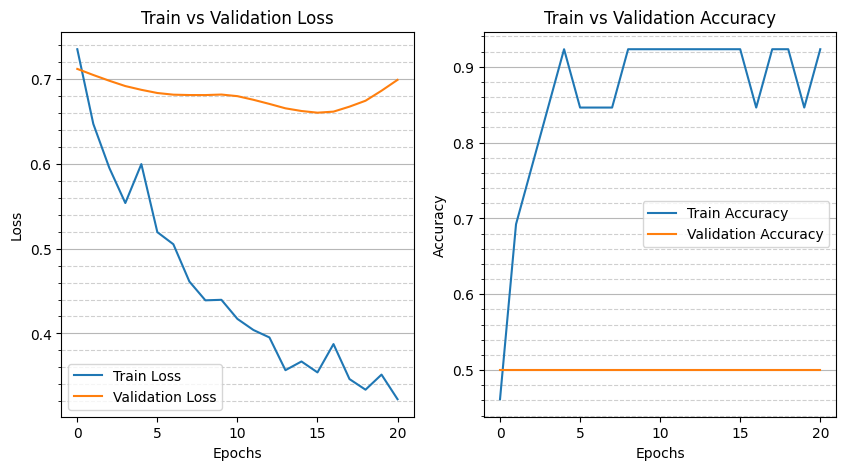

In [192]:
#NN_plot(folder_route, num_class, epoch, fig_size)
pm.NN_plot("/tf/notebooks/SCARS/NN/test/relu", 2, 100, (10, 5))

In [193]:
#TS_NN_model(folder_route, epoch, batch_size, activation_function, drop_out, filters, kernel, num_classes, X_train, Y_train, metric, validation_split)
    # binatry classification: binary_accuracy
    # multi classification: sparse_categorical_accuracy
ts_cam.TS_NN_model("/tf/notebooks/SCARS/NN/test/relu", 100, 10, "relu", 0.2, 16, 3, 3, TS_NN_NP_X_train_min_len, TS_NP_Y_train_min_len_multi, "sparse_categorical_accuracy", 0.3)

Restoring model weights from the end of the best epoch: 32.
Epoch 37: early stopping


In [194]:
TS_NN_NP_min_len_loss, TS_NN_NP_min_len_acc = vrm.TS_NN_evaluate("/tf/notebooks/SCARS/NN/test/relu", 100, TS_NN_NP_X_test_min_len, TS_NP_Y_test_min_len_multi)

1/1 [==============================] - 0s 203ms/step - loss: 1.0312 - sparse_categorical_accuracy: 0.5556


In [195]:
print(TS_NN_NP_min_len_loss)
print(TS_NN_NP_min_len_acc)

1.0311917066574097
0.5555555820465088


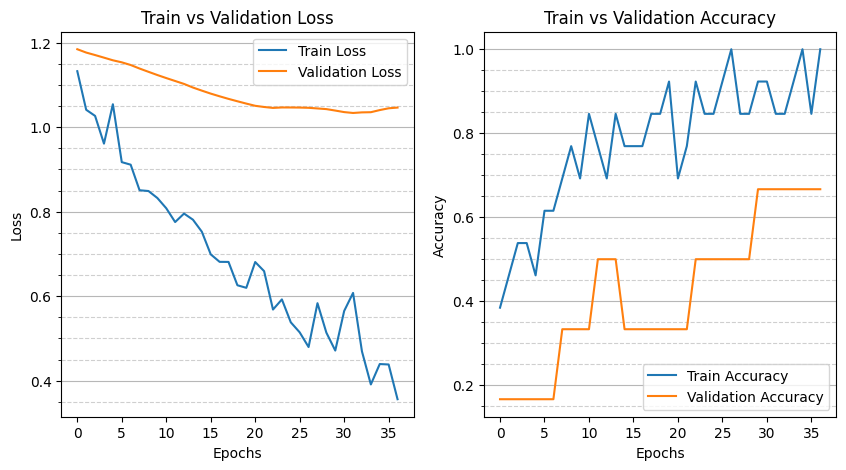

In [196]:
pm.NN_plot("/tf/notebooks/SCARS/NN/test/relu", 3, 100, (10, 5))